# SL-PINN for 1D-1V Vlasov-Poisson: Landau damping

Production notebook for the Landau damping test (corresponging to the manuscript Section 4.2). We compare the learned
inverse flow map (SL-PINN) against a numerical (Strang splitting) reference solution: the phase-space solution and error map at four times, and the electric-field decay
and mass preservation over the full horizon. Functions are in
`slpinn_landau1d.py`.

Flags below: `MODE` selects the SL-PINN map parameterisation; `SKIP_TRAINING`
reuses a model saved under `outputs/` for post-processing only.

In [1]:
import json
import time
from pathlib import Path

import matplotlib
try:
    get_ipython  # noqa: F821
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "4")


import slpinn_landau1d as sl

MODE = "symplectic"        # "symplectic" | "normalizing" | "soft"
SKIP_TRAINING = True      # True: load a saved model from outputs/ and only plot
QUICK = False               # True: minutes on GPU; False: paper-scale settings

sl.use_paper_style()
device = sl.pick_device()
dtype = sl.default_dtype(device)
torch.manual_seed(0)

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
SL_PATH = OUT / f"landau_sl_{MODE}.pt"

if QUICK:
    SL_ITERS, EVAL_NX, EVAL_NV = 1500, 128, 128
else:
    SL_ITERS, EVAL_NX, EVAL_NV = 3000, 256, 256

print(f"mode={MODE}  skip_training={SKIP_TRAINING}  quick={QUICK}  device={device}")

mode=symplectic  skip_training=True  quick=False  device=cuda


## SL-PINN (train or load)

In [2]:
if SKIP_TRAINING:
    assert SL_PATH.exists(), f"missing {SL_PATH}; run once with SKIP_TRAINING=False"
    model, problem, f_fn, cfg = sl.load_model(SL_PATH, device=str(device))
    print(f"loaded {SL_PATH}")
else:
    cfg = sl.TrainConfig(detach_field=True, lambda_energy=1e-3, lambda_ampere=1.0,
                        n_per_slice=512, sampling="support",
                        gating="linear", normalize_inputs=False,
                        field_nx=32, log_every=50,         # 128 -> 32: free, rho has only k=1,2
                        iters=SL_ITERS)       

    trainer = sl.Trainer(cfg)
    trainer.train()
    trainer.save(SL_PATH)
    model, problem, f_fn = trainer.model, trainer.problem, trainer.f_fn
    print(f"saved {SL_PATH}  ({sl.n_params(model)} params, {trainer.train_time:.1f}s)")

det_rows = sl.det_statistics(model, problem,
                             torch.linspace(0, problem.t_final, 4, device=device, dtype=dtype),
                             n_points=512)
print("max |det - 1| over t:", max(r["max"] for r in det_rows))


def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"{name}.{ext}")

loaded outputs/landau_sl_symplectic.pt
max |det - 1| over t: 1.3322676295501878e-15


## Reference solution

Strang splitting semi-Lagrangian solver (double
precision). The four plot times feed the phase-space figure; a fine time grid
feeds the electric-field and mass diagnostics.

In [3]:
times = torch.tensor(problem.plot_times, device=device, dtype=dtype)  # [3.75,7.5,11.25,15]
f_ref, xg, vg = sl.reference_on_grid(problem, times, EVAL_NX, EVAL_NV,
                                     OUT, device, dtype, verbose=True)
f_sl = sl.evaluate_f_on_grid(f_fn, times, xg, vg)
tvals = times.tolist()
print("reference grid:", tuple(f_ref.shape))

reference grid: (4, 256, 256)


## Figure 6 - solution and error map

At each time: a slice of f along x (at v near 0), a slice along v (at x near 0,
showing the velocity-space filamentation), and the error map f_SL - f_NUM.

| t | l2 | linf | rel_l2 |
|---|---|---|---|
| 3.75 | 0.002422 | 0.007959 | 0.01576 |
| 7.5 | 0.003267 | 0.01035 | 0.02126 |
| 11.25 | 0.003398 | 0.01052 | 0.0221 |
| 15 | 0.003417 | 0.01049 | 0.02223 |


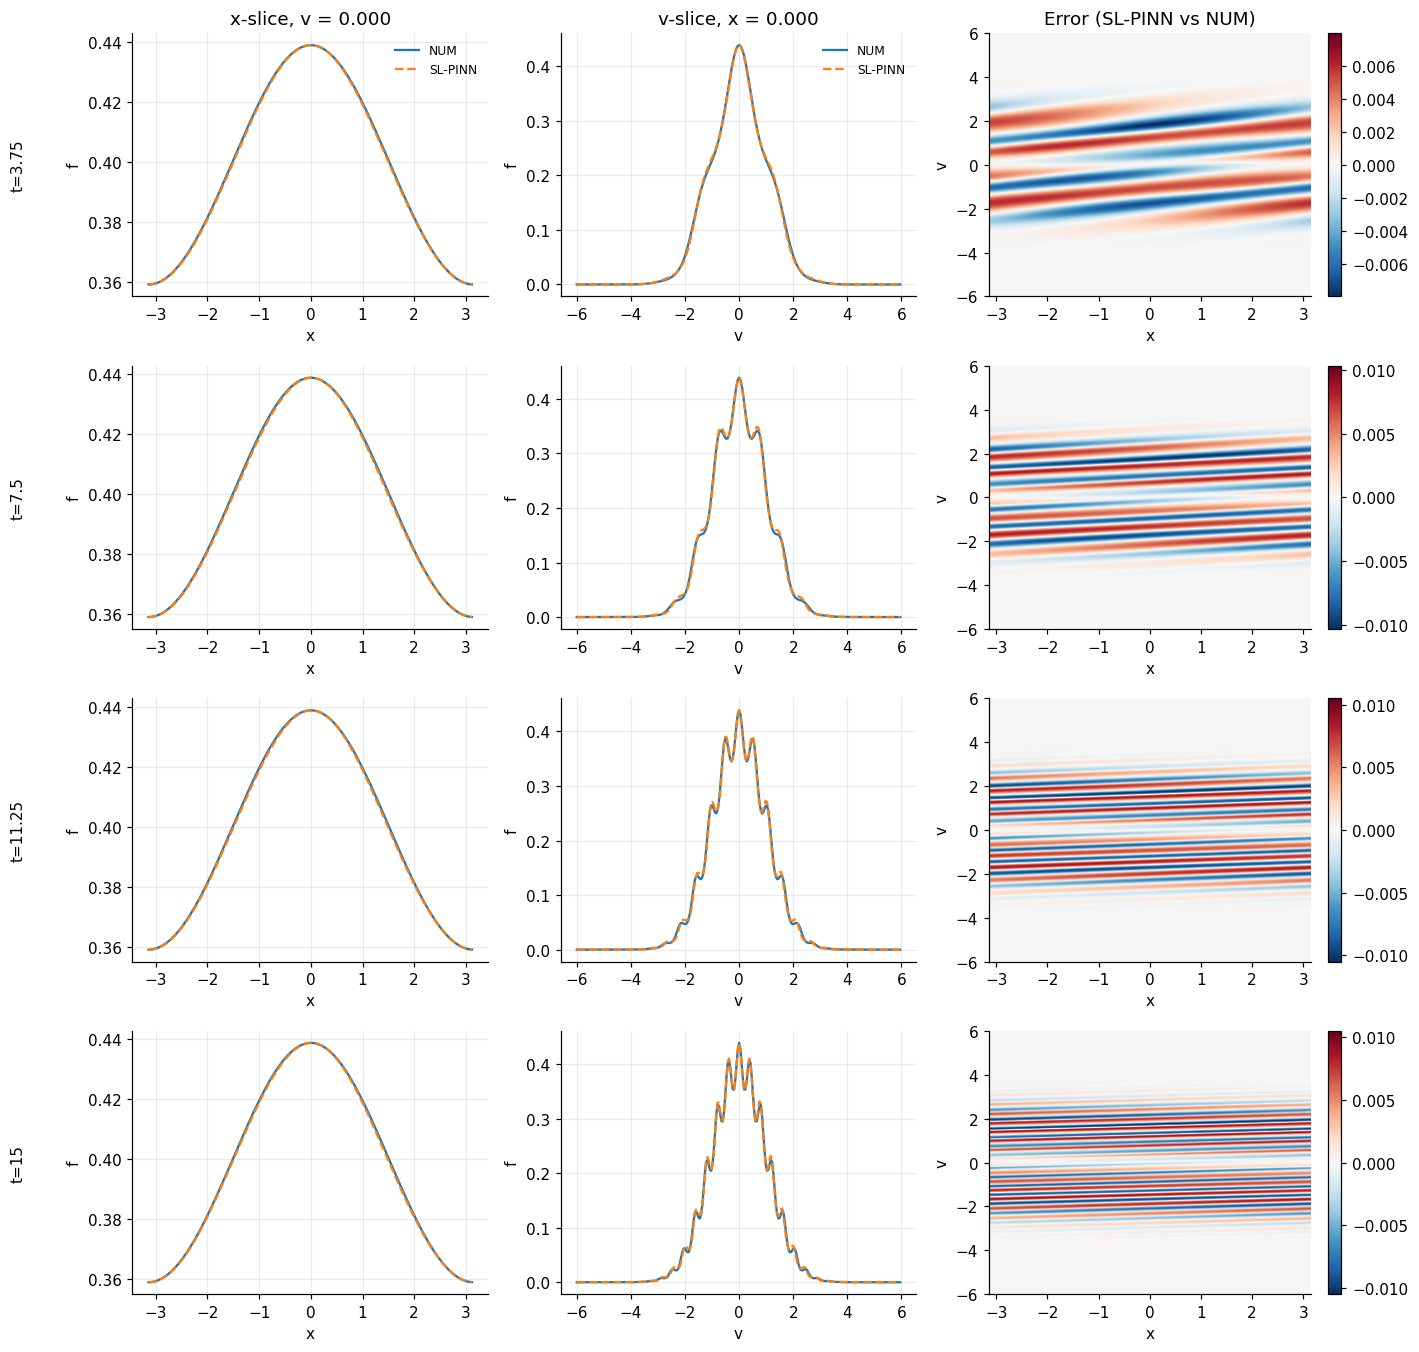

In [4]:
rows_err = sl.error_table(f_sl, f_ref, times)
print(sl.markdown_table(rows_err, columns=["t", "l2", "linf", "rel_l2"]))

iv = int((vg.abs()).argmin())           # v index closest to 0
ix = int((xg.abs()).argmin())           # x index closest to 0
ext = [problem.x_lo, problem.x_hi, problem.v_lo, problem.v_hi]
n = len(tvals)
fig, axes = plt.subplots(n, 3, figsize=(13, 3.1 * n))
for i in range(n):
    ax_x, ax_v, ax_e = axes[i]
    ax_x.plot(xg.cpu(), f_ref[i, :, iv].cpu(), "-", color="C0", lw=1.5, label="NUM")
    ax_x.plot(xg.cpu(), f_sl[i, :, iv].cpu(), "--", color="C1", lw=1.5, label="SL-PINN")
    ax_v.plot(vg.cpu(), f_ref[i, ix, :].cpu(), "-", color="C0", lw=1.5, label="NUM")
    ax_v.plot(vg.cpu(), f_sl[i, ix, :].cpu(), "--", color="C1", lw=1.5, label="SL-PINN")
    #err = ((f_sl[i] - f_ref[i])/ (f_ref[i] + 1e-12)).T.cpu()
    err = (f_sl[i] - f_ref[i]).T.cpu()
    m = float(err.abs().max())
    im = ax_e.imshow(err, origin="lower", extent=ext, aspect="auto",
                     cmap="RdBu_r", vmin=-m, vmax=m)
    fig.colorbar(im, ax=ax_e, fraction=0.046)
    ax_e.grid(False); ax_e.set_xlabel("x"); ax_e.set_ylabel("v")
    ax_x.set_xlabel("x"); ax_x.set_ylabel("f")
    ax_v.set_xlabel("v"); ax_v.set_ylabel("f")
    if i == 0:
        ax_x.set_title(f"x-slice, v = {float(vg[iv]):.3f}")
        ax_v.set_title(f"v-slice, x = {float(xg[ix]):.3f}")
        ax_e.set_title("Error (SL-PINN vs NUM)")
        ax_x.legend(fontsize=8); ax_v.legend(fontsize=8)
    ax_x.text(-0.32, 0.5, f"t={tvals[i]:g}", transform=ax_x.transAxes,
              rotation=90, va="center", ha="center")
fig.tight_layout()
save_fig(fig, "fig6_solution_error")
plt.show()

## Figure 7 - energy and mass preservation

The RMS electric field E_rms(t) against the reference over the whole horizon,
and the absolute mass-preservation error |mass(t) - mass(0)|. With the
symplectic (det=1) map the mass is conserved to machine precision, so the error
curve sits at ~0; the soft-penalty formulation (`MODE="soft"`) instead drifts by
~1e-2 over the horizon.

damping rate gamma:  SL-PINN -0.756   reference -0.899
max |mass(t) - mass(0)|: 9.54e-07


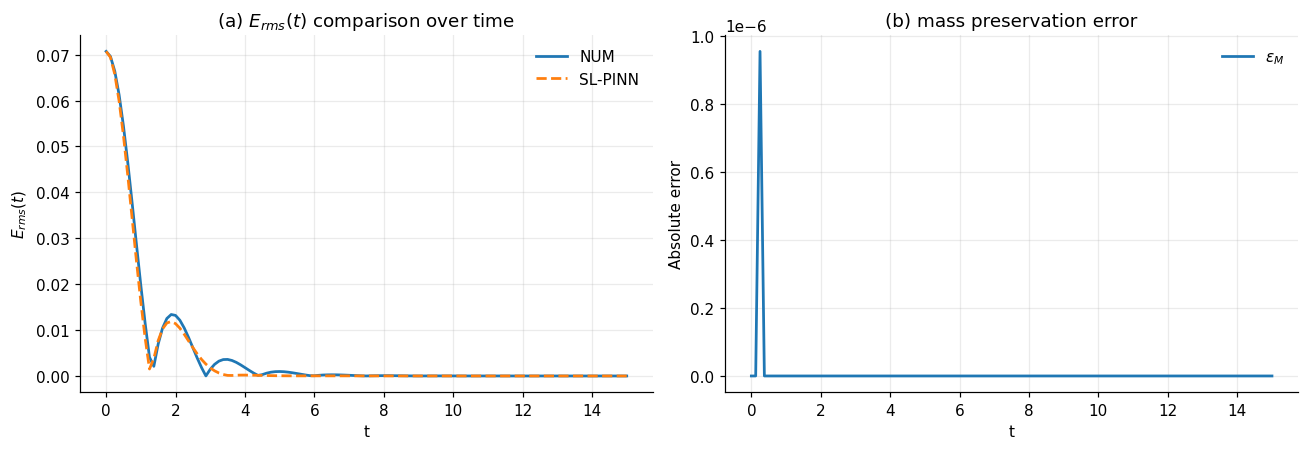

figures written to outputs


In [5]:
nt_c = 121 if not QUICK else 81
tc = torch.linspace(0, problem.t_final, nt_c, device=device, dtype=dtype)
fr_c, xc, vc = sl.reference_on_grid(problem, tc, 128, 128, OUT, device, dtype)
fm_c = sl.evaluate_f_on_grid(f_fn, tc, xc, vc)
cons_m = sl.conservation_from_f_grid(fm_c, tc, xc, vc, problem.length, True)
cons_r = sl.conservation_from_f_grid(fr_c, tc, xc, vc, problem.length, True)

g_m = sl.fit_damping_rate(tc, cons_m.e_rms)
g_r = sl.fit_damping_rate(tc, cons_r.e_rms)
mass_err = (cons_m.mass - cons_m.mass[0]).abs()
print(f"damping rate gamma:  SL-PINN {g_m:.3f}   reference {g_r:.3f}")
print(f"max |mass(t) - mass(0)|: {mass_err.max().item():.2e}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(tc.cpu(), cons_r.e_rms.cpu(), "-", color="C0", lw=1.8, label="NUM")
ax1.plot(tc.cpu(), cons_m.e_rms.cpu(), "--", color="C1", lw=1.8, label="SL-PINN")
ax1.set_xlabel("t"); ax1.set_ylabel(r"$E_{rms}(t)$")
ax1.set_title("(a) $E_{rms}(t)$ comparison over time")
ax1.legend()
ax2.plot(tc.cpu(), mass_err.cpu(), "-", color="C0", lw=1.8, label=r"$\varepsilon_M$")
ax2.set_xlabel("t"); ax2.set_ylabel("Absolute error")
ax2.set_title("(b) mass preservation error")
ax2.legend()
fig.tight_layout()
save_fig(fig, "fig7_energy_mass")
plt.show()

print("figures written to", OUT)

##  Conservation of mass, momentum and energy (NUM vs SL-PINN)
Mass, momentum and energy drift compared with the numerical solution.


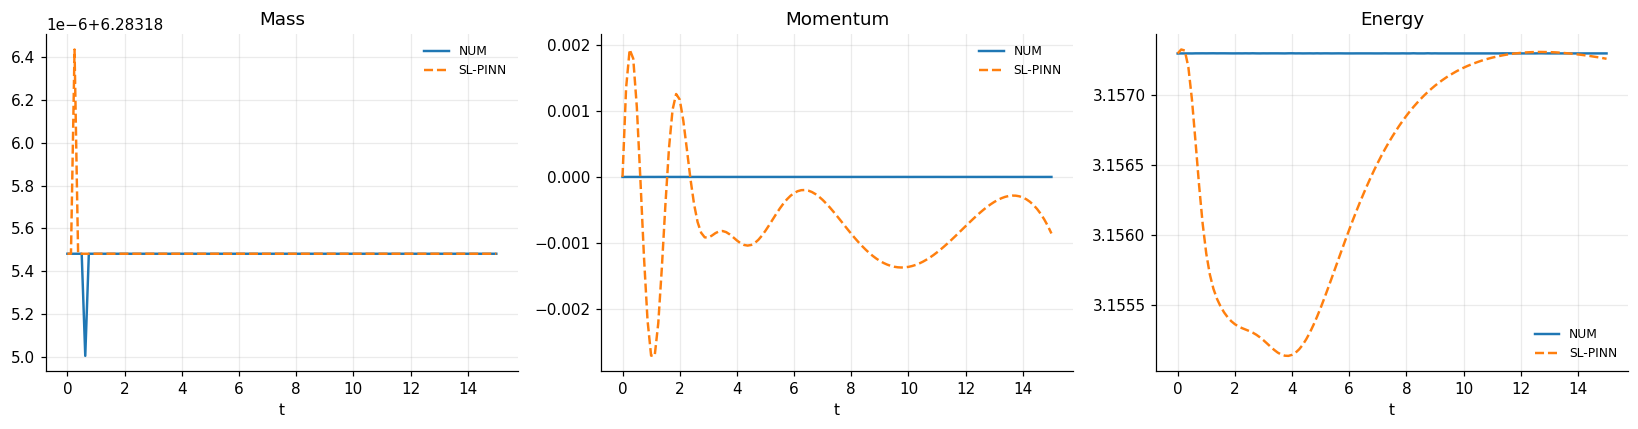

max |mass_SL - mass_NUM| = 9.537e-07
max |momentum_SL - momentum_NUM| = 2.712e-03
max |energy_SL - energy_NUM| = 2.167e-03


In [6]:
# Plot conservation of mass, momentum and energy (NUM vs SL-PINN)
fields = ["mass", "momentum", "energy"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, fld in zip(axes, fields):
    y_num = getattr(cons_r, fld)
    y_sl = getattr(cons_m, fld)
    ax.plot(tc.cpu(), y_num.cpu(), "-", color="C0", lw=1.6, label="NUM")
    ax.plot(tc.cpu(), y_sl.cpu(), "--", color="C1", lw=1.6, label="SL-PINN")
    ax.set_xlabel("t")
    ax.set_title(fld.capitalize())
    ax.legend(fontsize=8)
    ax.grid(True)

fig.tight_layout()
save_fig(fig, "fig_conservation_mass_momentum_energy")
plt.show()

# Print max absolute deviations for quick reference
for fld in fields:
    dev = (getattr(cons_m, fld) - getattr(cons_r, fld)).abs().max().item()
    print(f"max |{fld}_SL - {fld}_NUM| = {dev:.3e}")